# Demucs(HTDemucs) 구조 뜯어보기: 수업의 CNN · 인코더–디코더 · Attention · Transformer가 실제 모델 어디에 있나

**Claude Code판**(층별 텐서 모양·어텐션·SDR 실험)과 **ChatGPT판**(분석 대상 구분, 문제 정의, 소스 읽기 체크리스트, `apply_model` 조각 처리, 평가 관점, 실험 기록 템플릿)을 **합쳐서 중복을 없애고 순서를 다시 짠 것**입니다.*
앱의 `apply_model(...)` 한 줄 뒤에서 일어나는 일을 **직접 확인**합니다.

## 한눈에 보기

| 절 | 질문 | 어떻게 확인하나 | 얻는 것 |
|---|---|---|---|
| 0–1 | 무엇을, 어떤 원칙으로 보나? 문제는 무엇인가? | 저장소 역할 구분, 문제 정의 | 범위·원칙 |
| 2 | 수업 개념은 Demucs의 어디에 있을까? | 가설표(아래 실험으로 확인) | 가설 |
| 3 | 앱의 코드 한 줄이 라이브러리의 어느 클래스로 이어지나? | `inspect`, 15.4절 값과 대조 | 호출 경로 |
| 4 | 모델은 어떤 덩어리이고 `forward`는 어떤 순서로 부르나? | 모듈 트리·파라미터, `forward` 소스 | 구조 표·개념도 |
| 5 | 스펙트로그램 가지의 입력(STFT)은 어떤 해상도인가? | 수식과 계산, 앱·Whisper 설정과 비교 | 해상도 표 |
| 6 | 실험 입력은 어떻게 만드나? | 정답을 아는 합성 믹스 | 실험 입력 |
| 7 | 데이터 모양은 층마다 어떻게 변하나? | `forward hook` | **텐서 모양 표** |
| 8 | Attention은 어디에서 무엇과 무엇을 연결하나? | 어텐션 모듈 hook, 토이 계산 | self/cross 표 |
| 9 | 긴 소리는 어떻게 처리하나? (`split`, `overlap`) | `apply_model` 소스, 조각 계산 | 조각 처리 |
| 10 | 분리가 실제로 되었나? 고정 필터와 무엇이 다른가? | 스펙트로그램, 대역별 비율, SDR | 숫자·그림 |
| 11 | 무엇으로 평가해야 하나? | WER·SDR·시간·청취 비교 | 평가 관점 |
| 12 | 내가 이해한 것 / 아직 모르는 것 | 직접 채우기 | **강사님께 할 질문**, 기록 템플릿 |

**표기**: **[확인]** 이 노트북 코드나 설치된 소스로 직접 확인, **[일반 지식]** 논문·문서에서 일반적으로 알려진 것(확인 필요), **[추정]** 내 추측, **[미확인]** 아직 못 함.
**데이터 규칙**: 상업곡의 음원·가사는 쓰지 않습니다. 입력은 **내가 직접 쓴 예문의 TTS 소리 + 직접 만든 합성 반주**뿐입니다. 곡 파일·파생 오디오·스펙트로그램은 로컬 `data/`·`results/`에만 두고 커밋하지 않습니다. 출력을 지운 정리본을 커밋합니다.
**걸리는 시간**: 대부분 몇 초이고, **7절(모델 한 번 실행)이 CPU에서 약 40초~1분**입니다. 위에서 아래로 실행하세요.

## 0. 분석 대상과 원칙

| 저장소 | 분석 목적 |
|---|---|
| [facebookresearch/demucs](https://github.com/facebookresearch/demucs) | **모델 자체**의 구조·레이어·`forward`·추론 알고리즘 |
| [greenkey20/song-lingo](https://github.com/greenkey20/song-lingo) | **우리 서비스**가 모델을 어떻게 로드·전처리·호출·후처리하는가(`separate.py`) |

"Demucs 구조 분석"의 중심은 원본 저장소의 `HTDemucs`입니다. 하지만 구조만 읽으면 우리 앱이 실제로 어떤 입력을 주고 어떤 출력을 쓰는지 놓치므로 `separate.py`도 함께 따라갑니다.

**분석 원칙**
1. 프로젝트 문서 15.4절의 수치는 **그 컴퓨터·그 버전에서 확인한 값**이지 모든 버전의 상수가 아닙니다. 이 노트북에서 다시 확인해 대조합니다.
2. **개념적 설명**과 **설치된 패키지에서 확인한 구현 사실**을 구분합니다. 속성 이름만 보고 동작을 추측하지 않고 `forward()`의 호출 순서를 따라갑니다.
3. "분리하면 STT가 좋아진다"는 결론을 미리 가정하지 않습니다.

## 1. 문제 정의: 음악 소리 분리 (source separation)

혼합 음악은 여러 소스가 합쳐진 신호입니다.

$$x(t) = s_{vocals}(t) + s_{drums}(t) + s_{bass}(t) + s_{other}(t)$$

Demucs는 혼합 신호 $x$를 입력받아 학습된 모델로 각 소스의 추정값을 출력합니다. SongLingo가 vocals를 쓰는 목적은 ① Whisper가 반주 없이 가사를 인식하도록 비교하고 ② **"보컬만 듣기"**(원어민 발음을 반주 없이 듣는 보조) 용도입니다.

**실험적 배경 [확인: 프로젝트 문서 15.4절의 기록, 8구간 tiny 비교]**: 분리한 vocals의 micro WER은 **0.606**으로 원곡(**0.506**)보다 전체로는 **나빴고**, 구간별로는 갈렸습니다. 즉 **분리는 가설이지 항상 유효한 전처리가 아닙니다.** 또 20초 구간 분리에 CPU로 **약 65초**가 걸렸고, 내 곡 파일은 대부분 WMA 32 kHz·약 33 kbps라 분리 이전부터 정보가 적습니다. 이는 해당 데이터·환경의 결과이며 Demucs 전체 성능에 대한 일반 결론이 아닙니다.

## 2. 먼저 가설: 수업 개념은 Demucs의 어디에 있을까? (아래 실험으로 하나씩 확인)

| 수업 | 개념 | Demucs에서 찾을 곳 (가설) |
|---|---|---|
| 02·03강 | FFT, STFT, 스펙트로그램 | 스펙트로그램 가지의 입력(`nfft=4096`, `hop=1024`) → 5절 |
| 006 CNN | 합성곱으로 국소 패턴 추출, 채널↑·크기↓ | 인코더 4층(`Conv`) → 7절 |
| 010 Seq2Seq | 인코더로 압축 → 디코더로 복원 | `encoder`/`decoder`, 같은 단계끼리 **건너뛰기 연결** → 4·7절 |
| 011 Attention | $\mathrm{softmax}(QK^\top/\sqrt d)V$ | `crosstransformer` 안의 `MultiheadAttention` → 8절 |
| 012 Transformer | 셀프 어텐션 + 피드포워드 층 쌓기 | `MyTransformerEncoderLayer`, `CrossTransformerEncoderLayer` → 4·8절 |
| 009 RNN/LSTM | 순서대로 상태 전달 | 이전 세대 Demucs(BLSTM). **현재 모델에 LSTM이 있나?** → 4절에서 셉니다 |

In [1]:
# ── 환경 확인 ──────────────────────────────────────────────────────────────
# 하는 일: 프로젝트 루트를 찾아 작업 폴더로 하고(노트북이 experiments/ 아래에 있어도 루트의 모듈을 import하려고),
#          demucs·torch 버전과 장치를 출력한다. [수업에 없음] demucs, torch(수업은 Keras/TensorFlow)
# 주의: 이 노트북에서는 Whisper(faster-whisper)를 import하지 않는다. 같은 커널에서 Whisper와 Demucs(torch)를 함께 불러
#       OpenMP 충돌로 커널이 죽은 적이 있기 때문이다(개발환경 이슈노트 #15).
import os, sys, time, inspect, re
from pathlib import Path
here = Path.cwd().resolve()
for p in [here, *here.parents]:
    if (p / "practice.py").exists():
        os.chdir(p); sys.path.insert(0, str(p)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display      # 표를 예쁘게 보여 주는 노트북 함수
import torch, demucs
import theme, separate, visualisation
theme.apply_style()
print("프로젝트 루트:", Path.cwd().name, "| demucs", demucs.__version__, "| torch", torch.__version__, "| 장치: CPU(GPU 없음)")

프로젝트 루트: song-lingo | demucs 4.1.0 | torch 2.2.2 | 장치: CPU(GPU 없음)


## 3. 앱의 코드 한 줄 → 라이브러리의 어느 클래스?

`separate.py`의 `separate_vocals`가 하는 일 (6단계):
1. `load_clip()` — 입력 소리를 44.1 kHz 스테레오 `(2, 표본)`으로 변환
2. `_load_model()` — `get_model("htdemucs")`로 가져와 `eval()`
3. NumPy 배열을 Tensor로 바꾸고 **배치 축을 추가** → `(1, 2, 표본)`
4. 채널 평균 신호의 평균·표준편차로 **정규화**
5. `apply_model(..., split=True, overlap=0.25)` 호출
6. 정규화를 되돌리고 `model.sources`에서 `vocals`만 고름

이 셀에서 그 소스를 직접 봅니다.

In [2]:
# ── 3절-1: 앱의 호출 코드 ────────────────────────────────────────────────────
# 하는 일: separate.py의 모델 로딩 함수와 분리 함수의 소스를 그대로 보여 준다(위 6단계가 코드의 어느 줄인지 대조).
print(inspect.getsource(separate._load_model))
print(inspect.getsource(separate.separate_vocals))

def _load_model(name=MODEL_NAME):
    """Demucs 모델을 한 번만 읽어 캐시한다. 처음에는 인터넷에서 내려받는다(이후에는 캐시 사용)."""
    if name not in _models:
        from demucs.pretrained import get_model   # 지연 import: demucs·torch는 분리할 때만 필요
        model = get_model(name)
        model.eval()                               # 학습 모드가 아니라 추론 모드(드롭아웃 등 끔)
        _models[name] = model
    return _models[name]

def separate_vocals(clip, sr=MODEL_SR, model=None, apply_fn=None, device="cpu", overlap=0.25):
    """(2, 샘플) 스테레오 파형 → 보컬만 남긴 (2, 샘플) float32 파형.

    - 입력은 모델의 sr(44.1 kHz)이어야 한다(load_clip의 기본값). 다르면 ValueError.
    - 정규화: Demucs 명령줄 도구와 같이 '채널 평균'의 평균·표준편차로 입력을 정규화했다가 결과에 되돌린다.
    - split=True: 긴 소리를 조각으로 나눠 처리(메모리 절약), overlap=0.25: 조각이 25% 겹치게 해서 이음새를 부드럽게 한다.
    - 완전한 무음이면(표준편차 0) 모델을 돌리지 않고 무음을 돌려준다.
    - model, apply_fn은 테스트에서 가짜를 넣는 자리다. 평소에는 None.
    """
    if clip.ndim != 2 or clip.shape[0] != 2:
        raise ValueError("(2, 샘플) 모양의 스테레오 파형이 필요합니다.")
    if sr != MODEL_SR:
        raise ValueEr

**확인 질문과 답** (코드를 읽고 정리)
- **`separate.py`는 모델 내부를 구현하나?** 아니요. **사전학습 모델을 불러서 호출**할 뿐입니다 [확인: 위 소스]. 모델 구현은 `demucs` 패키지에 있습니다.
- **`(2, 표본)`과 `(1, 2, 표본)`의 축은?** `(채널, 표본)`과 `(배치, 채널, 표본)`입니다. 배치 축은 "한 번에 몇 개 소리를 처리하나"이고 앱은 1개씩 처리합니다 [확인: 소스의 `[None]`].
- **`model.eval()`과 `torch.no_grad()`는 같은 기능인가?** 아닙니다. `eval()`은 층의 **동작 모드**(드롭아웃을 끄고 배치 정규화는 저장된 통계를 씀), `no_grad()`는 **기울기 기록을 끄는 것**(메모리·시간 절약)입니다. 추론에는 둘 다 씁니다 [일반 지식].

In [3]:
# ── 3절-2: 모델 가져오기와 메타데이터 ─────────────────────────────────────────
# 하는 일: get_model이 돌려주는 객체의 종류를 확인하고, 15.4절에 기록해 둔 값과 지금 값을 대조 표로 만든다.
from demucs.pretrained import get_model
bag = get_model("htdemucs"); bag.eval()          # eval(): 추론 모드 (수업 6강 model.predict와 같은 상태)
model = bag.models[0]
print("get_model이 돌려준 것:", type(bag).__name__, "| 안에 든 모델 수:", len(bag.models), "| 가중치:", bag.weights)
print("실제 모델 클래스:", type(model).__name__)
total = sum(p.numel() for p in model.parameters())
meta = pd.DataFrame([
    ("패키지", "demucs 4.1.0", f"demucs {demucs.__version__}"),
    ("내부 클래스", "HTDemucs (외부 wrapper BagOfModels)", f"{type(model).__name__} (wrapper {type(bag).__name__})"),
    ("파라미터", "약 42.0M", f"{total / 1e6:.1f}M"),
    ("depth / channels", "4 / 48", f"{model.depth} / {model.channels}"),
    ("nfft / hop_length", "4096 / 1024", f"{model.nfft} / {model.hop_length}"),
    ("입력", "44.1 kHz stereo", f"{model.samplerate} Hz, 채널 {model.audio_channels}"),
    ("segment", "약 7.8초", f"{float(model.segment)}초"),
    ("분리하는 소리", "drums·bass·other·vocals", ", ".join(model.sources)),
], columns=["항목", "15.4절 기록값", "지금 확인한 값"])
display(meta)

/opt/anaconda3/envs/voice-ai/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


get_model이 돌려준 것: BagOfModels | 안에 든 모델 수: 1 | 가중치: [[1.0, 1.0, 1.0, 1.0]]
실제 모델 클래스: HTDemucs


,항목,15.4절 기록값,지금 확인한 값
0,패키지,demucs 4.1.0,demucs 4.1.0
1,내부 클래스,HTDemucs (외부 wrapper BagOfModels),HTDemucs (wrapper BagOfModels)
2,파라미터,약 42.0M,42.0M
3,depth / channels,4 / 48,4 / 48
4,nfft / hop_length,4096 / 1024,4096 / 1024
5,입력,44.1 kHz stereo,"44100 Hz, 채널 2"
6,segment,약 7.8초,7.8초
7,분리하는 소리,drums·bass·other·vocals,"drums, bass, other, vocals"


In [4]:
# ── 3절-3: 소스 위치 ─────────────────────────────────────────────────────
# 하는 일: 읽어야 할 클래스·함수가 라이브러리의 어느 파일 몇 번째 줄에 있는지 알려 준다(나중에 직접 열어 읽으려고).
from demucs import htdemucs, transformer, apply, hdemucs
targets = {
    "get_model (모델 가져오기)": get_model,
    "apply_model (조각 나눠 적용)": apply.apply_model,
    "HTDemucs (전체 모델, forward)": htdemucs.HTDemucs,
    "HDecLayer (디코더 층, 건너뛰기 연결)": hdemucs.HDecLayer,
    "CrossTransformerEncoder (가운데 변환기 묶음)": transformer.CrossTransformerEncoder,
    "MyTransformerEncoderLayer (셀프 어텐션 층)": transformer.MyTransformerEncoderLayer,
    "CrossTransformerEncoderLayer (교차 어텐션 층)": transformer.CrossTransformerEncoderLayer,
}
for name, obj in targets.items():
    path = inspect.getsourcefile(obj); line = inspect.getsourcelines(obj)[1]
    print(f"{name:44s} {Path(path).parent.name}/{Path(path).name}:{line}")

get_model (모델 가져오기)                          demucs/pretrained.py:58
apply_model (조각 나눠 적용)                       demucs/apply.py:145
HTDemucs (전체 모델, forward)                    demucs/htdemucs.py:27
HDecLayer (디코더 층, 건너뛰기 연결)                   demucs/hdemucs.py:256
CrossTransformerEncoder (가운데 변환기 묶음)         demucs/transformer.py:526
MyTransformerEncoderLayer (셀프 어텐션 층)         demucs/transformer.py:271
CrossTransformerEncoderLayer (교차 어텐션 층)      demucs/transformer.py:380


## 4. 구조 한눈에: 모델은 어떤 덩어리이고 `forward`는 어떤 순서로 부르나

**소스 읽기 체크리스트**

| 코드 위치 | 확인할 내용 |
|---|---|
| `__init__` | 입력 채널, depth, FFT, segment 설정 |
| `encoder` / `decoder` | 스펙트로그램 가지의 feature map 변화 |
| `tencoder` / `tdecoder` | 파형 가지의 텐서 변화 |
| `crosstransformer` | 두 가지 사이 정보 교환 방식 |
| `forward()` | 실제 모듈 호출 순서와 최종 출력 모양 |
| `apply_model()` | 조각 분할, 겹침, 결과 결합 → 9절 |

In [5]:
# ── 4절-1: 모듈 트리와 파라미터 수 ───────────────────────────────────────────
# 하는 일: 모델 바로 아래 덩어리(named_children)와 각 덩어리의 파라미터 수·비율, 층 종류별 개수를 센다.
rows = []
for name, child in model.named_children():
    n = sum(p.numel() for p in child.parameters())
    rows.append({"덩어리": name, "클래스": type(child).__name__, "층 수": len(child) if hasattr(child, "__len__") else "", "파라미터(만 개)": round(n / 1e4, 1)})
df = pd.DataFrame(rows)
df["비율(%)"] = (df["파라미터(만 개)"] * 1e4 / total * 100).round(1)
display(df)
print(f"총 파라미터 {total/1e6:.1f}M")
count = lambda cls: sum(isinstance(m, cls) for m in model.modules())
print("MultiheadAttention:", count(torch.nn.MultiheadAttention), "| Conv1d:", count(torch.nn.Conv1d), "| Conv2d:", count(torch.nn.Conv2d), "| LSTM:", count(torch.nn.LSTM))

,덩어리,클래스,층 수,파라미터(만 개),비율(%)
0,encoder,ModuleList,4,142.5,3.4
1,decoder,ModuleList,4,456.3,10.9
2,tencoder,ModuleList,4,142.4,3.4
3,tdecoder,ModuleList,4,220.9,5.3
4,freq_emb,ScaledEmbedding,,2.5,0.1
5,channel_upsampler,Conv1d,,19.7,0.5
6,channel_downsampler,Conv1d,,19.7,0.5
7,channel_upsampler_t,Conv1d,,19.7,0.5
8,channel_downsampler_t,Conv1d,,19.7,0.5
9,crosstransformer,CrossTransformerEncoder,,3155.0,75.1


총 파라미터 42.0M
MultiheadAttention: 10 | Conv1d: 80 | Conv2d: 12 | LSTM: 0


**[확인: 11-06 실행]** 총 약 **4,198만 개**, 소리 4개, **`nn.LSTM`은 0개**(현재 모델에 LSTM 없음; 소스에는 이전 세대의 `BLSTM` 클래스가 남아 있음 → 수업 009 RNN과 "예전에는 LSTM, 지금은 Transformer"로 연결, 세대별 설명은 [일반 지식]).
**파라미터의 약 75%(3,155만 개)가 가운데 `crosstransformer`** 에 있고, 인코더·디코더(CNN)는 합쳐서 약 22%입니다. 학습된 숫자의 대부분이 Attention(Transformer) 쪽에 있어서, 수업의 CNN만으로는 이 모델의 무게중심을 설명하지 못합니다.

In [6]:
# ── 4절-2: forward 호출 순서 추적 ────────────────────────────────────────────
# 하는 일: HTDemucs.forward 소스에서 "어느 모듈을 어떤 순서로 부르는지"를 보여 주는 줄만 뽑는다(속성 이름이 아니라 실제 호출 순서를 보려고).
src = inspect.getsource(htdemucs.HTDemucs.forward).splitlines()
keys = re.compile(r"self\.(_spec|_magnitude|tencoder|encoder|freq_emb|crosstransformer|decoder|tdecoder|_mask|_ispec)|rearrange|saved|pop\(")
for i, l in enumerate(src):
    if keys.search(l) and not l.strip().startswith("#"):
        print(f"{i:3d} {l.rstrip()[:118]}")

 11         z = self._spec(mix)
 12         mag = self._magnitude(z).to(mix.device)
 30         saved = []  # skip connections, freq.
 31         saved_t = []  # skip connections, time.
 32         lengths = []  # saved lengths to properly remove padding, freq branch.
 33         lengths_t = []  # saved lengths for time branch.
 34         for idx, encode in enumerate(self.encoder):
 37             if idx < len(self.tencoder):
 40                 tenc = self.tencoder[idx]
 44                     saved_t.append(xt)
 50             if idx == 0 and self.freq_emb is not None:
 54                 emb = self.freq_emb(frs).t()[None, :, :, None].expand_as(x)
 55                 x = x + self.freq_emb_scale * emb
 57             saved.append(x)
 58         if self.crosstransformer:
 61                 x = rearrange(x, "b c f t-> b c (f t)")
 63                 x = rearrange(x, "b c (f t)-> b c f t", f=f)
 66             x, xt = self.crosstransformer(x, xt)
 69                 x = rearrange(x, "b

### 구조 개념도 (소스를 읽은 뒤의 내 정리 — 7절의 실제 모양과 맞춰 봅니다)

```text
             섞인 소리 (2채널, 44.1 kHz)
                   │
        ┌──────────┴───────────┐
   [시간(파형) 가지]       [스펙트로그램 가지]
   tencoder 4층 (Conv1d)   STFT(nfft 4096) → 실수 4채널 (cac)
        │                  encoder 4층 (Conv2d)
        │                       │
        └──── crosstransformer (5층) ────┘      ← 두 가지의 정보를 Attention으로 주고받음
              self-attn → cross-attn → self → cross → self
        ┌──────────┴───────────┐
   tdecoder 4층 (ConvTranspose1d)   decoder 4층 (ConvTranspose2d)
        │      ↑ 같은 단계의 인코더 출력을 **더함**(건너뛰기 연결)   │
        └──────── 두 가지 결과를 더함 ────────┘
                   │
         drums / bass / other / vocals
```

소스로 확인한 것 [확인]
- **건너뛰기 연결은 "더하기"** 입니다: 디코더 층 `HDecLayer.forward`에 `x = x + skip`이 있습니다(이어 붙이기가 아님). `forward`에서 인코더 출력을 `saved`에 쌓았다가 `saved.pop(-1)`로 꺼내 같은 단계의 디코더에 넘깁니다.
- **가운데 변환기 입력은 `rearrange(x, "b c f t -> b c (f t)")`로 주파수×시간을 한 줄로 펼친 것**입니다 → 스펙트로그램 가지의 토큰 수 = 주파수 칸 × 시간 칸 (7·8절에서 숫자 확인).
- **`cac=True`이면 `_mask`가 마스크를 곱하지 않습니다.** 소스 주석: "`m` is actually a full spectrogram and `z` is ignored" — 디코더 출력이 **복소수 스펙트로그램 자체**이고 이를 `_ispec`(역 STFT)으로 파형으로 되돌립니다.
- **왜 두 가지(파형 + 스펙트로그램)인가?** 파형은 시간 모양(타악기의 순간적 타격 등)을, 스펙트로그램은 주파수 구성(배음 줄무늬 등)을 잘 보여 주어 서로 정보가 다르기 때문입니다 [일반 지식, 논문의 동기 설명]. 각 가지의 역할을 단정하지 않고 모양으로 검증합니다.

## 5. 스펙트로그램 가지의 입력 = STFT: 시간·주파수 해상도

$$X(m,k)=\sum_{n=0}^{N-1}x[n+mH]\,w[n]\,e^{-j2\pi kn/N}$$

$N$은 창(FFT) 길이, $H$는 hop(창을 옮기는 간격)입니다(수업 03강의 STFT). 창이 길수록 **주파수 해상도↑·시간 해상도↓** 입니다. 같은 STFT를 쓰는 세 곳을 비교해 봅니다.

In [7]:
# ── 5절: STFT 설정 비교 ───────────────────────────────────────────────────────
# 하는 일: (창 길이, hop, 표본화 주파수)로 주파수 간격(sr/N), 창 길이(ms), hop 길이(ms), 한 프레임이 담는 주파수 칸 수(N/2)를 계산한다.
# 비교 대상: Demucs(이 모델), 우리 앱의 소리 모양 그림(visualisation.py), Whisper의 입력(faster-whisper 특징 추출기: 창 400·hop 160·16 kHz [확인, 11-06])
cfg = [("Demucs htdemucs", model.samplerate, model.nfft, model.hop_length),
       ("앱 소리 모양 그림 (16 kHz)", 16000, visualisation.FRAME_LENGTH, visualisation.HOP_LENGTH),
       ("Whisper 입력 (16 kHz)", 16000, 400, 160)]
tab5 = pd.DataFrame([{"설정": n, "창 N": N, "hop H": H, "주파수 간격(Hz)": round(sr / N, 2), "창 길이(ms)": round(N / sr * 1000, 1),
                      "hop(ms)": round(H / sr * 1000, 1), "주파수 칸(N/2)": N // 2} for n, sr, N, H in cfg])
display(tab5)

,설정,창 N,hop H,주파수 간격(Hz),창 길이(ms),hop(ms),주파수 칸(N/2)
0,Demucs htdemucs,4096,1024,10.77,92.9,23.2,2048
1,앱 소리 모양 그림 (16 kHz),512,128,31.25,32.0,8.0,256
2,Whisper 입력 (16 kHz),400,160,40.00,25.0,10.0,200


Demucs는 **창이 매우 길고**(약 93 ms, 주파수 간격 약 10.8 Hz) 음악의 낮은 음과 배음을 세밀하게 구분하려는 설정으로 보이며, 말소리용 설정(Whisper 25 ms 창)과 다릅니다 [추정: 용도 차이로 해석]. 입력 주파수 칸 **2048**은 `nfft 4096`의 절반(0 Hz~Nyquist)이고, 시간 칸은 표본 수 ÷ hop입니다 [확인: 7절 모양과 대조].

## 6. 실험 입력 만들기: 정답을 아는 믹스

상업곡은 "정답 보컬"이 없어서 분리 품질을 숫자로 못 잽니다. 그래서 **내가 직접 쓴 예문의 TTS 소리(= 정답 "목소리")** 에 **직접 만든 합성 반주(저음 + 타악기 소리)** 를 더해 믹스를 만듭니다. 그러면 분리 결과를 정답과 비교할 수 있습니다.

**주의**: Demucs는 *노래* 보컬로 학습한 모델이라 말소리·합성 반주에서는 실제 곡과 다르게 동작할 수 있습니다. 이 노트북의 숫자는 "구조 관찰과 평가 방법 연습"용이고 실제 곡의 성능으로 일반화하지 않습니다.

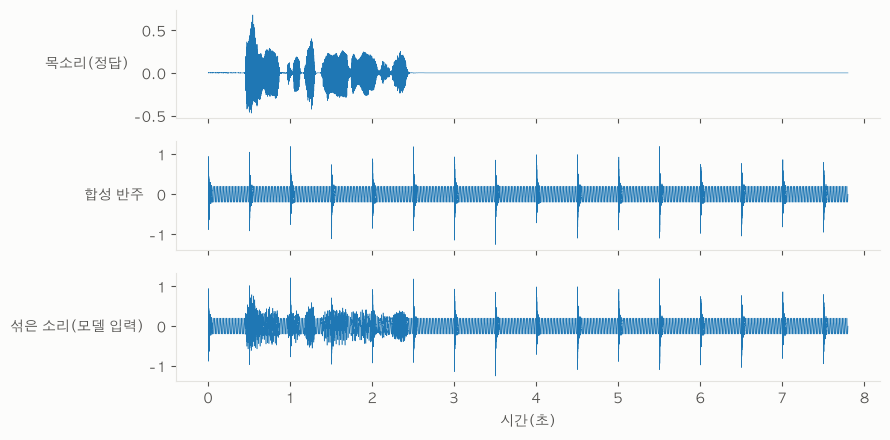

믹스 모양: (2, 343980) | 길이 7.8 초


In [8]:
# ── 6절: 합성 믹스 만들기 ────────────────────────────────────────────────────
# 하는 일: data/tts_cache/s01.wav(직접 쓴 예문 1번의 TTS)를 44.1 kHz 스테레오로 읽어 3초를 목소리(정답)로 쓰고,
#          55 Hz 저음 + 0.5초마다 울리는 잡음 타격을 반주로 더해 7.8초 믹스를 만든다(7.8초 = 모델의 학습 구간 길이).
SR = separate.MODEL_SR                                  # 44100
N = int(float(model.segment) * SR)                       # 343980 표본
voice = np.zeros((2, N), np.float32)
speech = separate.load_clip("data/tts_cache/s01.wav", 0.0, 3.0)    # (2, 표본): 앱의 구간 읽기 함수 재사용
voice[:, :speech.shape[1]] = speech[:, :N]
t = np.arange(N) / SR
rng = np.random.default_rng(0)                           # 시드 고정: 매번 같은 반주
bass = 0.2 * np.sin(2 * np.pi * 55 * t)
drums = np.zeros(N)
for k in range(0, N, SR // 2):
    L = min(int(0.05 * SR), N - k)
    drums[k:k + L] += rng.standard_normal(L) * np.exp(-np.arange(L) / (0.01 * SR)) * 0.4
accomp = np.stack([bass + drums] * 2).astype(np.float32)
mix = voice + accomp
fig, ax = plt.subplots(3, 1, figsize=(9, 4.5), sharex=True)
for a, x, name in zip(ax, [voice[0], accomp[0], mix[0]], ["목소리(정답)", "합성 반주", "섞은 소리(모델 입력)"]):
    a.plot(t, x, lw=0.4, color=theme.WAVEFORM); a.set_ylabel(name, rotation=0, ha="right", va="center")
ax[-1].set_xlabel("시간(초)"); plt.tight_layout(); plt.show()
print("믹스 모양:", mix.shape, "| 길이", round(N / SR, 2), "초")

## 7. 데이터의 모양은 층마다 어떻게 변하나 (forward hook)

**forward hook**은 "층이 계산을 끝낼 때마다 나에게 알려 줘"라고 걸어 두는 함수입니다. 모델을 고치지 않고 층의 입력·출력 모양을 기록할 수 있습니다. 여기서는 인코더·디코더·가운데 변환기·어텐션 모듈에 hook을 겁니다. **이 셀이 모델을 실제로 한 번 실행합니다(CPU 약 40초~1분).** 이 한 번의 실행 결과가 10절의 분리 결과로도 쓰입니다.

[수업에 없음] `register_forward_hook`: PyTorch의 기능으로, Keras의 중간 층 출력을 보려고 `Model(inputs, layer.output)`을 만드는 것과 같은 목적입니다.

In [9]:
# ── 7절-1: hook을 걸고 모델을 한 번 실행 ──────────────────────────────────────
# 하는 일: (1) 인코더/디코더/변환기 층의 입력·출력 모양, (2) 어텐션 모듈의 질의(query)·키(key) 모양을 기록한다.
#          (3) 같은 실행의 결과를 stems(분리된 4개 소리)로 저장한다. 입력 정규화는 separate.separate_vocals와 같은 방식.
def shape_of(o):
    if isinstance(o, torch.Tensor): return tuple(o.shape)
    if isinstance(o, (tuple, list)): return [shape_of(i) for i in o]
    return None
layer_rec, attn_rec, hooks = [], [], []
layer_names = [f"{p}.{i}" for p in ("tencoder", "encoder", "decoder", "tdecoder") for i in range(4)] + ["crosstransformer"]
for name, mod in model.named_modules():
    if name in layer_names:
        hooks.append(mod.register_forward_hook(lambda m, a, o, n=name: layer_rec.append((n, [shape_of(x) for x in a if x is not None and not isinstance(x, int)], shape_of(o)))))
    if isinstance(mod, torch.nn.MultiheadAttention):
        def h(m, args, kwargs, out, n=name):
            q = args[0] if args else kwargs["query"]; k = args[1] if len(args) > 1 else kwargs["key"]
            attn_rec.append((n, tuple(q.shape), tuple(k.shape)))
        hooks.append(mod.register_forward_hook(h, with_kwargs=True))

x = torch.from_numpy(mix)[None]                                  # (1, 2, 표본) = 배치 1개
ref = x.mean(1); mean, std = ref.mean(), ref.std()
t0 = time.time()
with torch.no_grad():                                            # 기울기 계산을 끄면 메모리·시간이 줄어든다
    stems = model((x - mean) / std) * std + mean                 # (1, 4, 2, 표본): 4개 소리
elapsed = time.time() - t0
for h_ in hooks: h_.remove()                                     # hook 정리(다음 실행에 영향 없게)
print(f"모델 한 번 실행: {elapsed:.0f}초 | 출력 모양 {tuple(stems.shape)} = (배치, 소리 4개, 채널 2, 표본)")

모델 한 번 실행: 37초 | 출력 모양 (1, 4, 2, 343980) = (배치, 소리 4개, 채널 2, 표본)


In [10]:
# ── 7절-2: 층별 모양 표 ───────────────────────────────────────────────────────
# 하는 일: 기록한 모양을 표로 보여 준다. 파형 가지는 (배치, 채널, 시간), 스펙트로그램 가지는 (배치, 채널, 주파수, 시간) 모양이다.
tab = pd.DataFrame([{"층": n, "입력 모양": s_in[0] if len(s_in) == 1 else s_in, "출력 모양": s_out} for n, s_in, s_out in layer_rec])
pd.set_option("display.max_colwidth", 80, "display.width", 200)
display(tab)

,층,입력 모양,출력 모양
0,tencoder.0,"(1, 2, 343980)","(1, 48, 85995)"
1,encoder.0,"(1, 4, 2048, 336)","(1, 48, 512, 336)"
2,tencoder.1,"(1, 48, 85995)","(1, 96, 21499)"
3,encoder.1,"(1, 48, 512, 336)","(1, 96, 128, 336)"
4,tencoder.2,"(1, 96, 21499)","(1, 192, 5375)"
5,encoder.2,"(1, 96, 128, 336)","(1, 192, 32, 336)"
6,tencoder.3,"(1, 192, 5375)","(1, 384, 1344)"
7,encoder.3,"(1, 192, 32, 336)","(1, 384, 8, 336)"
8,crosstransformer,"[(1, 512, 8, 336), (1, 512, 1344)]","[(1, 512, 8, 336), (1, 512, 1344)]"
9,decoder.0,"[(1, 384, 8, 336), (1, 384, 8, 336)]","[(1, 192, 32, 336), (1, 384, 8, 336)]"


### 모양이 알려 주는 것 (위 표의 숫자와 직접 대조하세요)

**[확인: 11-06 실행 값, 7.8초 믹스]**
- **시간(파형) 가지** `tencoder`: 길이 343,980 → 85,995 → 21,499 → 5,375 → 1,344 (한 층마다 **약 1/4**), 채널 2 → 48 → 96 → 192 → 384(첫 층 이후 **2배씩**). 수업 CNN의 "합성곱+스트라이드로 크기↓ 채널↑"과 같은 모양입니다.
- **스펙트로그램 가지** `encoder`: 입력 (4, 2048, 336)에서 주파수 칸이 2048 → 512 → 128 → 32 → 8(**1/4씩**), 시간 칸(336)은 유지, 채널 4 → 48 → 96 → 192 → 384.
  - 입력 채널 **4** = 스테레오 2채널 × (실수부, 허수부): `cac=True`가 복소수를 실수 2채널로 풀어 쌓기 때문입니다.
  - 주파수 칸 **2048** = `nfft 4096`의 절반, 시간 칸 **336** ≈ 343,980 ÷ `hop 1024` (5절 해상도와 일치).
- **디코더**는 인코더의 반대로 길이·주파수 칸을 4배씩 키우고 채널을 줄입니다. 마지막 `tdecoder.3`의 출력 (8, 343,980)은 **소리 4개 × 채널 2**가 원래 길이로 복원된 것입니다. 스펙트로그램 쪽 마지막 `decoder.3` 출력 (16, 2048, 336)은 **소리 4 × 채널 2 × (실수·허수)** 로 읽을 수 있습니다 [추정: 16 = 4×2×2].
- **가운데 `crosstransformer`**: 두 가지가 같은 채널 수(512)로 맞춰져 들어갑니다(인코더의 384 → 512는 `forward`가 변환기 앞에서 부르는 `channel_upsampler`(스펙트로그램 가지, 펼친 `(f t)` 위에서)와 `channel_upsampler_t`(시간 가지)이고, 변환기 뒤에는 `channel_downsampler`로 다시 384로 줄입니다 [확인: 4절 `forward` 줄 번호 59~72]). 스펙트로그램 가지는 (512, 8, 336), 시간 가지는 (512, 1344)이고, 변환기에는 이것이 **한 줄로 펼쳐진 토큰**으로 들어갑니다(8절).

## 8. Attention은 어디에서 무엇과 무엇을 연결하나

`crosstransformer` 안에는 어텐션이 **10개**(스펙트로그램 쪽 5 + 시간 쪽 5) 있습니다. 층 이름의 `self_attn` / `cross_attn`을 보면 종류를 알 수 있습니다.
- **셀프 어텐션**: 질의(Q), 키(K), 값(V)가 **같은 가지**에서 나옴 → 같은 소리 안에서 멀리 떨어진 부분끼리의 관계.
- **교차 어텐션**: 질의는 한 가지에서, 키·값은 **다른 가지**에서 → 파형 가지가 스펙트로그램 가지를 "참조"하는 식으로 정보를 교환 [일반 지식, 논문 설명].

In [11]:
# ── 8절-1: 어텐션 모듈의 질의·키 길이 ────────────────────────────────────────
# 하는 일: 7절에서 hook으로 기록한 값을 표로 보여 준다. 질의 길이 ≠ 키 길이면 교차 어텐션이다.
at = pd.DataFrame(attn_rec, columns=["모듈", "질의(Q) 모양", "키(K) 모양"])
at["종류"] = at["모듈"].str.contains("cross_attn").map({True: "교차(cross)", False: "셀프(self)"})
at["가지"] = at["모듈"].str.contains("layers_t").map({True: "시간(파형)", False: "스펙트로그램"})
display(at[["가지", "모듈", "종류", "질의(Q) 모양", "키(K) 모양"]])
print("셀프:", (at["종류"] == "셀프(self)").sum(), "개 | 교차:", (at["종류"] == "교차(cross)").sum(), "개")

,가지,모듈,종류,질의(Q) 모양,키(K) 모양
0,스펙트로그램,crosstransformer.layers.0.self_attn,셀프(self),"(1, 2688, 512)","(1, 2688, 512)"
1,시간(파형),crosstransformer.layers_t.0.self_attn,셀프(self),"(1, 1344, 512)","(1, 1344, 512)"
2,스펙트로그램,crosstransformer.layers.1.cross_attn,교차(cross),"(1, 2688, 512)","(1, 1344, 512)"
3,시간(파형),crosstransformer.layers_t.1.cross_attn,교차(cross),"(1, 1344, 512)","(1, 2688, 512)"
4,스펙트로그램,crosstransformer.layers.2.self_attn,셀프(self),"(1, 2688, 512)","(1, 2688, 512)"
5,시간(파형),crosstransformer.layers_t.2.self_attn,셀프(self),"(1, 1344, 512)","(1, 1344, 512)"
6,스펙트로그램,crosstransformer.layers.3.cross_attn,교차(cross),"(1, 2688, 512)","(1, 1344, 512)"
7,시간(파형),crosstransformer.layers_t.3.cross_attn,교차(cross),"(1, 1344, 512)","(1, 2688, 512)"
8,스펙트로그램,crosstransformer.layers.4.self_attn,셀프(self),"(1, 2688, 512)","(1, 2688, 512)"
9,시간(파형),crosstransformer.layers_t.4.self_attn,셀프(self),"(1, 1344, 512)","(1, 1344, 512)"


셀프: 6 개 | 교차: 4 개


**읽는 법**: 모양은 `(배치, 토큰 수, 차원)`입니다. 스펙트로그램 가지의 토큰 수는 **주파수 칸 × 시간 칸 = 8 × 336 = 2,688**, 시간 가지는 **1,344**입니다 [확인: 위 표]. **교차 어텐션에서는 질의 쪽 토큰 수와 키 쪽 토큰 수가 다릅니다**(예: 질의 2,688 · 키 1,344) = 서로 다른 표현의 정보를 섞는다는 증거입니다. 층 순서는 self → cross → self → cross → self라서 셀프 6개, 교차 4개입니다.

### 수업의 Attention 식을 눈으로: 토큰 4개짜리 작은 예

위 어텐션 모듈 안의 핵심 계산은 수업 011강의 이 식입니다. **토큰 4개**로 직접 계산해 봅니다.

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d}}\right)V$$

In [12]:
# ── 8절-2: 작은 어텐션 계산 (numpy) ──────────────────────────────────────────
# 하는 일: 토큰 4개, 차원 8의 Q·K·V로 점수 → softmax → 가중합을 직접 계산한다. 실제 모델은 이것을 토큰 수천 개, 헤드 여러 개로 한다.
rng = np.random.default_rng(1)
Q, K, V = (rng.standard_normal((4, 8)) for _ in range(3))
score = Q @ K.T / np.sqrt(Q.shape[1])                    # (4, 4): 질의 i가 키 j를 얼마나 보나
w = np.exp(score - score.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)     # softmax: 각 줄의 합이 1
out = w @ V                                               # (4, 8): 값(V)의 가중합
print("가중치(각 줄의 합 = 1):\n", w.round(2), "\n줄 합:", w.sum(1).round(2))
print("출력 모양:", out.shape, "| 질의 4개 각각이 '키 4개'를 섞어 새 벡터를 만든다")
tokens = 8 * 336
print(f"스펙트로그램 가지 셀프 어텐션의 점수 표: {tokens} x {tokens} = {tokens * tokens:,} 칸 (토큰 수의 제곱)")

가중치(각 줄의 합 = 1):
 [[0.19 0.21 0.36 0.24]
 [0.44 0.16 0.15 0.25]
 [0.24 0.29 0.29 0.18]
 [0.03 0.81 0.11 0.04]] 
줄 합: [1. 1. 1. 1.]
출력 모양: (4, 8) | 질의 4개 각각이 '키 4개'를 섞어 새 벡터를 만든다
스펙트로그램 가지 셀프 어텐션의 점수 표: 2688 x 2688 = 7,225,344 칸 (토큰 수의 제곱)


**연산량 감각** [확인: 값은 계산]: 점수 표가 **약 720만 칸**이고 토큰 수의 제곱으로 늘어서, 긴 소리를 한 번에 넣지 못하고 **7.8초 조각으로 나눠 처리**하는 이유 중 하나일 것입니다 [추정].

## 9. 긴 소리는 어떻게 처리하나: `split=True`, `overlap=0.25`

앱의 `separate_vocals`는 `apply_model(..., split=True, overlap=0.25)`를 부릅니다. 소스를 읽어 확인한 동작 [확인: `demucs/apply.py`]:
- `segment_length = int(samplerate × segment)` = 7.8초 분량의 표본 수 → **조각 하나의 길이**
- `stride = int((1 − overlap) × segment_length)` → 겹침 0.25이면 **조각을 75%씩만 옮김**(25%는 앞 조각과 겹침)
- 조각마다 모델을 따로 실행하고 **삼각형 가중치**(조각 가운데가 크고 가장자리가 작음)를 곱해 이어 붙인 뒤 **가중치 합으로 나눠** 정규화 → 이음새가 부드럽게 섞입니다.

        sum_weight = th.zeros(length, device=mix.device)
        segment_length: int = int(model.samplerate * segment)
        stride = int((1 - overlap) * segment_length)
        offsets = range(0, length, stride)
        scale = float(format(stride / model.samplerate, ".2f"))
        weight = th.cat([th.arange(1, segment_length // 2 + 1, device=device),
                         th.arange(segment_length - segment_length // 2, 0, -1, device=device)])
        assert len(weight) == segment_length
        weight = (weight / weight.max())**transition_power
            chunk = TensorChunk(mix, offset, segment_length)
            out[..., offset:offset + segment_length] += (
            sum_weight[offset:offset + segment_length] += weight[:chunk_length].to(mix.device)
        assert sum_weight.min() > 0
        out /= sum_weight
20초 입력 → 조각 4개 (조각 7.80초, 이동 5.85초)
60초 입력 → 조각 11개 (조각 7.80초, 이동 5.85초)


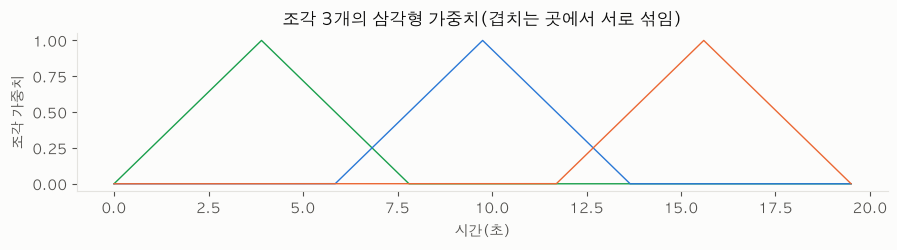

In [13]:
# ── 9절: 조각 처리 계산 ───────────────────────────────────────────────────────
# 하는 일: apply_model 소스의 핵심 줄을 보여 주고, 20초·60초 입력이 몇 조각으로 나뉘는지 같은 공식으로 계산한 뒤, 삼각형 가중치가 겹쳐 합이 1이 되는 모습을 그린다.
for l in inspect.getsource(apply.apply_model).splitlines():
    if re.search(r"segment_length|stride|offsets =|weight = |sum_weight|out /= sum_weight", l):
        print(l.rstrip()[:120])
seg_len = int(model.samplerate * float(model.segment)); stride = int((1 - 0.25) * seg_len)
for sec in (20, 60):
    length = sec * model.samplerate
    offs = list(range(0, length, stride))
    print(f"{sec}초 입력 → 조각 {len(offs)}개 (조각 {seg_len / model.samplerate:.2f}초, 이동 {stride / model.samplerate:.2f}초)")
# 삼각형 가중치 3개를 겹쳐 합이 1(정규화 후)이 되는 모양
w = np.concatenate([np.arange(1, seg_len // 2 + 1), np.arange(seg_len - seg_len // 2, 0, -1)]).astype(float); w /= w.max()
tot = stride * 2 + seg_len; acc = np.zeros(tot); fig, ax = plt.subplots(figsize=(9, 2.6))
for i in range(3):
    seg = np.zeros(tot); seg[i * stride:i * stride + seg_len] = w; acc += seg
    ax.plot(np.arange(tot) / model.samplerate, seg, lw=1, color=theme.SERIES[i])
ax.set_xlabel("시간(초)"); ax.set_ylabel("조각 가중치"); ax.set_title("조각 3개의 삼각형 가중치(겹치는 곳에서 서로 섞임)"); plt.tight_layout(); plt.show()

## 10. 분리가 실제로 되었나? 소리로 확인하고, 고정 필터와 비교

7절에서 얻은 `stems`(분리 결과)를 쓰고 정답(목소리)을 알고 있으므로 **그림 → 대역별 비율 → 숫자(SDR)** 순서로 봅니다.

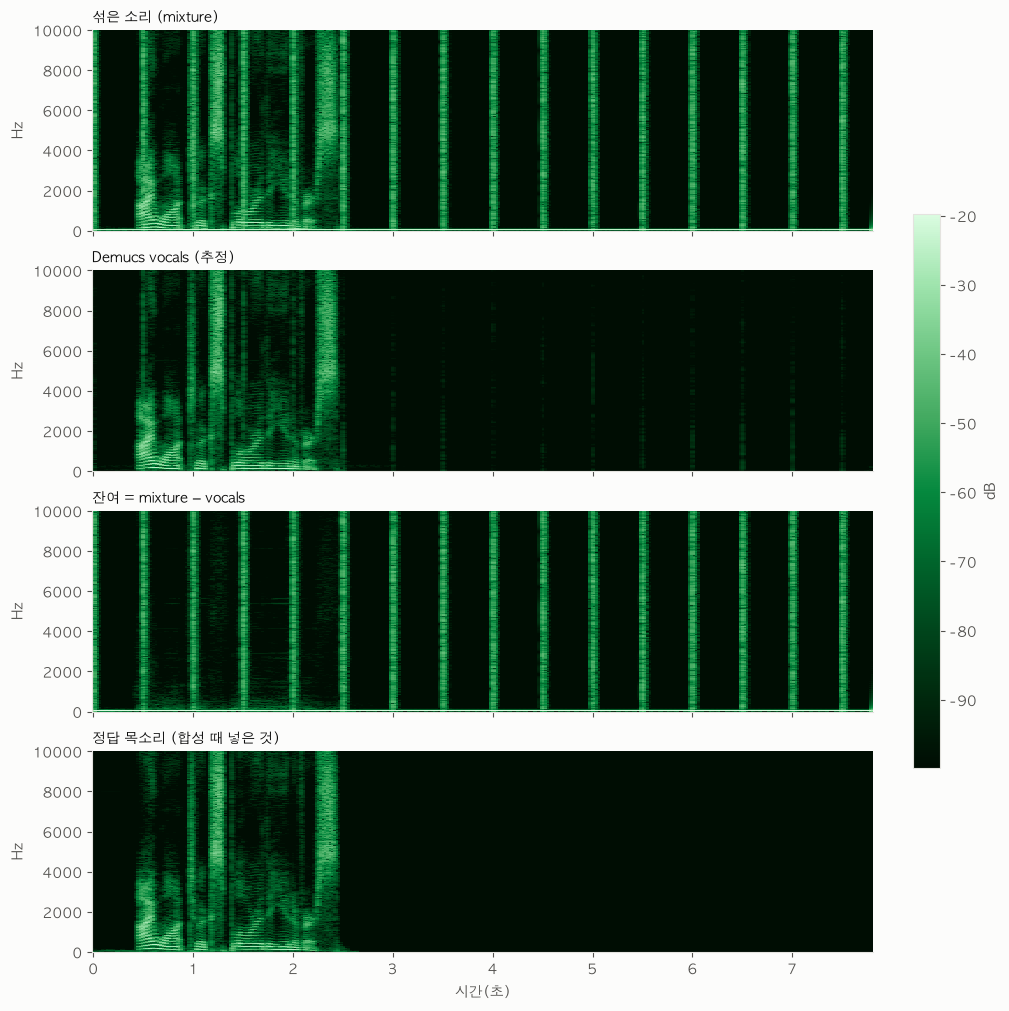

In [14]:
# ── 10절-1: 스펙트로그램 4종 비교 ─────────────────────────────────────────────
# 하는 일: 섞은 소리 / Demucs가 추정한 vocals / 잔여(mixture − vocals) / 정답 목소리의 스펙트로그램을 같은 설정(창 4096, 겹침 3072)과 같은 색 범위로 그린다.
# scipy.signal.stft: 수업 03강의 STFT를 라이브러리로 계산. 색은 프로젝트 공통 cmap(theme.CMAP_SPEC).
from scipy.signal import stft
voc = stems[0, model.sources.index("vocals")].numpy()
mono = lambda a: a.mean(0)
signals = [("섞은 소리 (mixture)", mono(mix)), ("Demucs vocals (추정)", mono(voc)),
           ("잔여 = mixture − vocals", mono(mix) - mono(voc)), ("정답 목소리 (합성 때 넣은 것)", mono(voice))]
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True, constrained_layout=True)
vmax = None
for ax, (title, sig) in zip(axes, signals):
    f, tt, z = stft(sig, fs=SR, nperseg=4096, noverlap=3072)
    db = 20 * np.log10(np.abs(z) + 1e-7)
    vmax = db.max() if vmax is None else vmax                     # 첫 그림(믹스)의 최댓값을 기준으로 4개의 색 범위를 같게
    im = ax.pcolormesh(tt, f, db, shading="auto", cmap=theme.CMAP_SPEC, vmin=vmax - 80, vmax=vmax)
    ax.set_ylim(0, 10000); ax.set_title(title, loc="left", fontsize=10); ax.set_ylabel("Hz")
axes[-1].set_xlabel("시간(초)"); fig.colorbar(im, ax=axes, label="dB", shrink=0.6); plt.show()

### 대역별 에너지 비율

대역마다 **(그 소리의 에너지 ÷ 섞은 소리의 에너지)** 를 봅니다. 정답 목소리의 비율이 "이상적인 분리"의 기준선입니다. 단, 이것은 **기술적 관찰값**입니다: 위상과 상관관계 때문에 "원곡에서 보컬이 차지하는 실제 비율"이라고 단정할 수 없고, 정답이 없는 실제 곡에서는 정확도를 평가할 수도 없습니다.

,대역(Hz),정답 목소리/믹스,Demucs vocals/믹스
0,0-100,0.013,0.013
1,100-200,0.383,0.382
2,200-400,0.967,0.958
3,400-800,0.942,0.929
4,800-1600,0.824,0.791
5,1600-3200,0.329,0.311
6,3200-6400,0.370,0.369
7,6400-12800,0.213,0.213
8,12800-22050,0.000,0.000


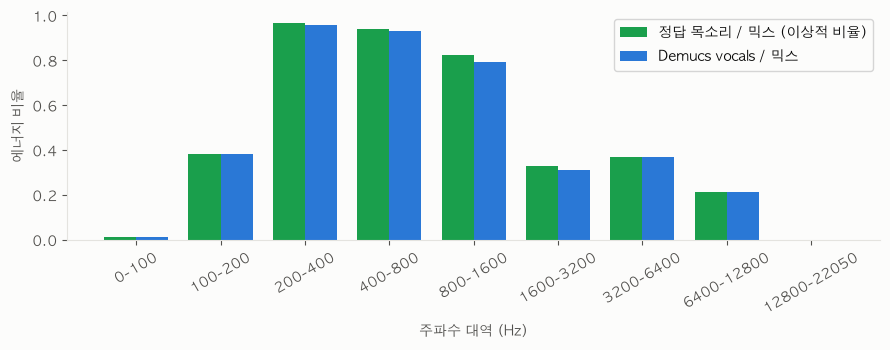

In [15]:
# ── 10절-2: 대역별 에너지 비율 (#35 ②의 작은 버전) ────────────────────────────
# 하는 일: 주파수 대역마다 (소리의 에너지 ÷ 섞은 소리의 에너지)를 표와 그림으로 보여 준다.
# visualisation.stft_power: 앱의 STFT 파워 계산(수업 3강 방식)을 그대로 재사용.
edges = [0, 100, 200, 400, 800, 1600, 3200, 6400, 12800, 22050]
def band_energy(x):
    hz, _t, p = visualisation.stft_power(x.mean(0), SR)
    return np.array([p[(hz >= lo) & (hz < hi)].sum() for lo, hi in zip(edges[:-1], edges[1:])])
e_mix, e_ref, e_voc = band_energy(mix), band_energy(voice), band_energy(voc)
labels = [f"{lo}-{hi}" for lo, hi in zip(edges[:-1], edges[1:])]
display(pd.DataFrame({"대역(Hz)": labels, "정답 목소리/믹스": (e_ref / e_mix).round(3), "Demucs vocals/믹스": (e_voc / e_mix).round(3)}))
xx = np.arange(len(labels)); wd = 0.38
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(xx - wd / 2, e_ref / e_mix, wd, label="정답 목소리 / 믹스 (이상적 비율)", color=theme.SERIES[0])
ax.bar(xx + wd / 2, e_voc / e_mix, wd, label="Demucs vocals / 믹스", color=theme.SERIES[1])
ax.set_xticks(xx); ax.set_xticklabels(labels, rotation=30); ax.set_xlabel("주파수 대역 (Hz)"); ax.set_ylabel("에너지 비율")
ax.legend(); plt.tight_layout(); plt.show()

### 숫자로 비교: SDR과 고정 대역통과 필터

"주파수 대역만으로 분리할 수 있는가?"를 확인하려고 **대역통과 필터를 대조군**으로 둡니다. **필터의 통과 대역은 결과를 보기 전에 정했습니다**(결과를 본 뒤 유리하게 바꾸지 않으려고): 200~4,000 Hz(말소리·보컬 중심 대역으로 짐작한 값 [추정])와 150~5,000 Hz(넓은 대역, 두 번째 후보) 두 가지입니다. 필터는 통과 대역 밖의 목소리 성분도 같이 지웁니다.

비교 기준 **SDR**(신호 대 왜곡비, 클수록 정답에 가까움): $\mathrm{SDR}=10\log_{10}\frac{\sum \text{정답}^2}{\sum(\text{정답}-\text{추정})^2}$ [일반 지식: 음원 분리 평가의 기본형]. **정답 stem이 있어야만 계산할 수 있습니다**(Demucs가 만든 vocals를 자기 자신의 정답으로 삼으면 성립하지 않음).

In [16]:
# ── 10절-3: SDR 비교와 잔여 검증 ──────────────────────────────────────────────
# 하는 일: 정답(voice)과 각 추정의 SDR을 계산한다. scipy.signal.butter: 버터워스 대역통과 필터(4차), sosfiltfilt: 앞뒤로 두 번 걸어 위상이 밀리지 않게.
# 또 잔여(mixture − vocals)가 나머지 3개 stem(drums+bass+other)의 합과 얼마나 같은지 본다(둘은 정확히 같을 이유가 없다: 모델의 근사).
# [수업에 없음] SDR, 버터워스 필터(수업은 FFT로 주파수를 보는 데까지)
from scipy.signal import butter, sosfiltfilt
def sdr(ref, est):
    return 10 * np.log10((ref ** 2).sum() / (((ref - est) ** 2).sum() + 1e-12))
def band(lo, hi):
    return sosfiltfilt(butter(4, [lo, hi], btype="bandpass", fs=SR, output="sos"), mix, axis=1).astype(np.float32)
res = pd.DataFrame({"방법": ["섞은 소리 그대로", "고정 대역통과 200~4000 Hz", "고정 대역통과 150~5000 Hz", "Demucs vocals"],
                    "SDR(dB)": [sdr(voice, mix), sdr(voice, band(200, 4000)), sdr(voice, band(150, 5000)), sdr(voice, voc)]}).round(2)
display(res)
rest = (stems[0, [i for i, s in enumerate(model.sources) if s != "vocals"]].sum(0)).numpy()     # drums+bass+other
resid_err = np.linalg.norm((mix - voc) - rest) / np.linalg.norm(mix - voc)
print(f"잔여(mixture−vocals)와 나머지 3개 stem 합의 상대 차이: {resid_err:.3f} (0이면 완전히 같음)")
for s_name in model.sources:
    e = stems[0, model.sources.index(s_name)].numpy()
    print(f"{s_name:7s} RMS = {np.sqrt((e ** 2).mean()):.4f}")

,방법,SDR(dB)
0,섞은 소리 그대로,-9.45
1,고정 대역통과 200~4000 Hz,2.98
2,고정 대역통과 150~5000 Hz,4.38
3,Demucs vocals,21.63


잔여(mixture−vocals)와 나머지 3개 stem 합의 상대 차이: 0.044 (0이면 완전히 같음)
drums   RMS = 0.0398
bass    RMS = 0.1418
other   RMS = 0.0038
vocals  RMS = 0.0493


### 이 합성 입력에서 나온 결과 [확인: 11-06 실행, 시드 고정, 이 입력에서만 해당]
- **SDR**: 섞은 소리 그대로 **−9.45 dB**, 고정 대역통과 200~4,000 Hz **2.98 dB**, 150~5,000 Hz **4.38 dB**, Demucs `vocals` **21.63 dB**. 단순한 주파수 필터는 통과 대역을 넓혀 봐도 개선이 작았고(두 후보 모두 5 dB 미만), 학습된 모델은 정답에 훨씬 가깝습니다. 사전에 정한 두 후보만 시험했으므로 다른 대역에서는 달라질 수 있습니다.
- **스펙트로그램 4종 (10절-1 그림)**: 섞은 소리에는 0.5초마다 **세로줄(타악기)** 과 목소리의 **배음 줄무늬**가 함께 보입니다. Demucs `vocals`에서는 세로줄이 거의 사라지고 목소리 구간(약 0.4~2.5초)만 남으며, 잔여에는 반대로 세로줄만 남습니다. 정답 목소리와 `vocals`의 모양이 거의 같습니다 [확인: 그림].
- **대역별 에너지 비율**: 정답 목소리의 비율(초록)은 200~1,600 Hz에서 0.8~1에 가깝고, 1,600~12,800 Hz에서는 0.2~0.35로 **0과 1 사이**입니다. 이유는 합성 타악기(잡음)가 넓은 대역에 걸쳐 있어서 **목소리와 같은 대역을 공유**하기 때문입니다. 그런데도 Demucs의 막대(파랑)가 정답 막대와 거의 겹칩니다. → "음역대가 달라서 분리된다"만으로는 설명이 안 되고, 같은 대역을 공유해도 분리된다는 증거입니다(**이 합성 입력에서만**; 실제 곡에서는 #35의 ①~③으로 확인해야 함 [미확인]).
- **잔여 검증**: 잔여(mixture − vocals)와 나머지 3개 stem(drums+bass+other)의 합은 **상대 차이 0.044**(약 4%)로 거의 같지만 **정확히 같지는 않습니다.** 각 stem이 모델의 독립된 추정이라 합이 믹스와 정확히 일치할 이유가 없기 때문입니다 [추정].
- **주의**: 입력이 말소리 + 합성 반주라 실제 노래의 성능으로 일반화하지 않습니다. SDR이 높게 나온 것은 쉬운 입력이기 때문일 수 있습니다 [추정].

## 11. 평가: 무엇으로 재야 하나 (WER과 분리 품질은 다릅니다)

| 평가 관점 | 방법 | 답하는 질문 | 이 노트북에서 |
|---|---|---|---|
| SongLingo의 목적 | WER / CER | 분리 후 STT가 정답 가사에 가까워졌나? | 아직 안 함(실제 곡 구간 필요, 15.4절 기록: 전체로는 악화) |
| 분리 자체 | SDR / SI-SDR | 추정 stem이 기준 stem에 얼마나 가까운가? | **합성 입력에서만** 계산(10절) |
| 처리 비용 | 지연 시간 / 실시간 대비 배수 | 실제 사용에 필요한 시간은? | 아래 셀 |
| 청취 | 주관 평가 | 반주 잔류·보컬 손실·인공음이 들리는가? | 사람이 직접 |

SDR/SI-SDR에는 **정답 vocals stem**이 필요하므로 정답이 없는 상업곡에는 쓸 수 없고, 그래서 우리 프로젝트는 청취와 STT의 WER/CER로 대신 비교합니다.

In [17]:
# ── 11절: 처리 시간 ───────────────────────────────────────────────────────────
# 하는 일: 7절에서 잰 시간을 오디오 길이로 나눠 "실시간 대비 배수"를 구하고 15.4절의 기록과 나란히 놓는다. 이 값은 이 PC(CPU)·이 입력의 값이다.
audio_sec = N / SR
print(f"이번 실행: 오디오 {audio_sec:.1f}초를 {elapsed:.0f}초에 처리 → 실시간의 약 {elapsed / audio_sec:.1f}배")
print("15.4절 기록: 20초 구간을 약 65초에 처리 → 약 3.2배 (CPU 스레드 2개, 프로세스 시작·모델 읽기 포함 여부는 [미확인])")

이번 실행: 오디오 7.8초를 37초에 처리 → 실시간의 약 4.8배
15.4절 기록: 20초 구간을 약 65초에 처리 → 약 3.2배 (CPU 스레드 2개, 프로세스 시작·모델 읽기 포함 여부는 [미확인])


## 12. 정리 (직접 채우는 칸)

### 오늘 코드로 확인한 사실 [확인]
- `get_model("htdemucs")`는 `BagOfModels`를 돌려주고 안에는 `HTDemucs` 하나가 있다. 파라미터 약 4,198만 개, **75%가 `crosstransformer`**.
- 시간 가지와 스펙트로그램 가지가 각각 4층 인코더/디코더를 갖고, 가운데 변환기 5층(self·cross 교대)이 둘을 잇는다. `nn.LSTM`은 0개, `MultiheadAttention`은 10개(셀프 6·교차 4).
- 건너뛰기 연결은 **더하기**(`x = x + skip`), 변환기 입력은 **주파수×시간을 한 줄로 펼친 토큰**, `cac=True`이면 **마스크가 아니라 복소수 스펙트로그램을 직접 출력**한다.
- `apply_model`은 7.8초 조각을 75%씩 옮기며(겹침 25%) 삼각형 가중치로 이어 붙인다.
- (직접 적기)

### 내가 이해한 것 (내 말로)
- 
- 

### 아직 이해하지 못한 것 → 강사님께 (두 노트북의 질문을 합쳐 중복을 없앴습니다. **굵은 글씨**가 우선 3개)
1. **두 가지(파형, 스펙트로그램)는 학습으로 서로 어떤 보완적인 표현을 얻나요?** 두 결과를 더해서 최종 소리를 만드는 이유는요? (지금 확인한 것: 각 가지의 모양, 마지막에 두 출력을 더함)
2. **CNN 인코더가 이미 국소 패턴을 뽑는데 왜 Attention이 또 필요한가요?** 파라미터의 75%가 변환기에 있는 것은 무슨 뜻인가요?
3. **건너뛰기 연결(더하기)** 은 복원에서 어떤 역할을 하나요? 수업 Seq2Seq(010)에 같은 장치가 있었나요?
4. 변환기에 들어갈 때 주파수×시간을 **한 줄로 펼친 토큰**(2,688개)으로 만드는데, 위치 정보(순서)는 어떻게 알려 주나요? 교차 어텐션의 질의와 키는 왜 서로 다른 가지에서 오고, 토큰 수가 달라도 계산이 되는 이유는요?
5. `cac=True`에서 모델이 마스크가 아니라 **복소수 스펙트로그램을 직접 예측**하는데, 왜 복소수를 실수 2채널로 풀어 다루나요?
6. 토큰 2,688개의 점수 표가 약 720만 칸입니다. 모델이 **7.8초 조각으로만 학습·동작**하는 것과 관련이 있나요?
7. 학습할 때 정답은 어떻게 주나요(손실 함수)? 정답 보컬이 없는 상업곡에 왜 잘 동작하나요?
8. 이전 세대 Demucs는 LSTM, 지금은 Transformer인 이유가 수업의 RNN → Attention 흐름과 같은 이야기인가요?
9. 우리 앱의 목적에는 **WER/CER 비교가 실용 평가로 충분**한가요? 분리 자체의 품질을 주장하려면 SDR/SI-SDR이 필요한가요?
10. (도전) 어텐션 **가중치를 직접 시각화**하고 싶은데 어떻게 꺼낼 수 있나요?

### 다음 단계
1. **#35의 ①**: 실제 시연 곡 구간 1개의 원곡·보컬·잔여 스펙트로그램과 WER/CER 비교(결과는 `results/`에만, 커밋 금지)
2. **Whisper 탐구**(같은 형식): 입력 로그 멜(창 400·hop 160·Mel 80개) 대 우리 그림(512·128·40), 디코더의 토큰 생성, 교차 어텐션과 단어 시간
3. 앱에서 겪은 현상을 구조로 설명하기(노래에서 VAD를 켜면 가사가 지워지는 일, 반복 루프, 언어 감지가 앞 30초만 보는 점)

### 실험 기록 템플릿 (실제 곡으로 #35를 할 때 복사해서 쓰기)
| 항목 | 기록 |
|---|---|
| 날짜 / 실험 ID | |
| Demucs 버전 / 모델 | |
| 익명 입력 ID / 구간 길이 | |
| 입력 표본화 주파수 / 채널 | |
| 실행 장치 / 스레드 수 | |
| mixture·vocals·residual 청취 평가 | |
| 처리 시간 | |
| STT 모델 / 설정 | |
| WER / CER (mixture) | |
| WER / CER (vocals) | |
| 관찰·해석·한계 | |
| 다음 질문 | |

### 완료 기준
- [x] 원본 Demucs 저장소와 SongLingo 통합 코드의 역할 차이를 설명한다(0절).
- [x] 설치된 `HTDemucs` 클래스의 실제 소스 경로와 핵심 모듈을 확인한다(3·4절).
- [x] `forward()`의 호출 순서를 추적한다(4절).
- [x] 주요 모듈의 입출력 텐서 모양을 한 번 기록한다(7절).
- [x] `apply_model(split=True, overlap=0.25)`의 분할·결합 방식을 설명한다(9절).
- [x] mixture/vocals/residual 스펙트로그램을 같은 설정으로 비교한다(10절, **합성 입력**).
- [ ] 실제 곡 구간으로 분리 전후 WER 결과와 한계를 설명한다(#35 ①, 다음 단계).

### 참고
- [facebookresearch/demucs — GitHub](https://github.com/facebookresearch/demucs) · 프로젝트 문서 15.4절 · `separate.py` · 이슈 #35
- 라이브러리 소스: `demucs/htdemucs.py`, `demucs/transformer.py`, `demucs/apply.py` (3절 셀에서 줄 번호 확인)
- 논문: Hybrid Transformers for Music Source Separation / Hybrid Spectrogram and Waveform Source Separation (세부 내용과 링크는 [미확인]; ChatGPT판이 단 arXiv 링크가 어느 논문인지는 읽기 전에 확인 필요)
- 발표에서는 **논문·저장소에서 확인한 내용**과 **이 프로젝트 환경에서 확인한 구현값**을 구분해서 말합니다.

---
[현재 서울 날짜 및 시각 2026-11-06 23:00:00]

핵심부터 말할게. 지금 Demucs를 이해하지 못하는 이유가 단순히 셀을 꼼꼼히 읽지 않았기 때문이라고 보기는 어려워. 첨부한 노트북을 실제로 확인해 보니, 더 근본적인 문제가 있어.

이 노트북은 Demucs의 구조를 관찰하는 데 필요한 정보와 실험을 상당히 많이 담고 있어. 그런데 관찰한 사실들을 하나의 작동 원리로 연결해 주는 설명이 부족해.

예를 들어 다음 사실들은 노트북에서 확인했어.

- 모델은 약 4,198만 개의 파라미터를 가진다.
- 파형과 스펙트로그램이라는 두 경로를 사용한다.
- CNN 인코더와 디코더가 각각 4층이다.
- 가운데 Transformer에는 Attention 모듈이 10개 있다.
- Attention에서 스펙트로그램 경로의 토큰은 2,688개, 파형 경로의 토큰은 1,344개다.
- 최종적으로 drums, bass, other, vocals 네 가지 소리를 출력한다.

그런데 이 숫자들을 알고 있다는 것과 Demucs가 어떻게 소리를 분리하는지 이해한다는 것은 서로 다른 일이야.

지금 필요한 것은 셀을 더 많이 실행하는 게 아니라, 하나의 입력 소리가 모델 안으로 들어가서 어떤 계산을 거쳐 네 개의 소리로 나오는지 머릿속에 그릴 수 있는 것이야.

# 1. 우선, 네가 지금 무엇을 이해하지 못하고 있는지 구분해 보자

첨부한 노트북의 내용을 기준으로 보면 이해해야 할 대상은 크게 네 가지야.

① 문제 정의

Demucs는 정확히 무엇을 해결하는가?

여러 악기와 보컬이 섞인 하나의 파형으로부터 원래의 개별 소리를 어떻게 추정하는가?

② 데이터 표현

왜 파형과 스펙트로그램을 모두 사용하는가?

같은 소리를 두 가지 형태로 표현하면 어떤 정보가 달라지는가?

③ 모델 구조

CNN과 Transformer는 각각 무엇을 계산하는가?

인코더, 디코더, Attention이 실제로 입력 데이터에 어떤 변화를 주는가?

④ 학습과 추론

모델은 어떻게 보컬과 반주를 구분하는 법을 배웠는가?

학습된 파라미터가 실제 추론 과정에서 어떻게 사용되는가?

현재 노트북은 ②와 ③의 내부 구조를 관찰하는 데 꽤 많은 분량을 할애하고 있어. 반면 네가 가장 먼저 잡아야 하는 ①과 ④는 상대적으로 약해.

특히 중요한 공백이 하나 있어.

노트북은 이미 학습이 끝난 Demucs를 가져와 실행하고 있어. 학습 과정 자체를 보여 주지는 않아.

따라서 지금 노트북을 실행하면서 확인할 수 있는 것은 주로 다음이야.

- 모델이 어떤 레이어로 구성되어 있는가?
- 입력 텐서가 각 레이어를 거치면서 어떻게 변하는가?
- 모델이 실제로 어떤 출력을 만들어 내는가?

하지만 다음 질문은 아직 충분히 답하지 못해.

- 모델은 무엇을 근거로 보컬이라고 판단하는가?
- 4,198만 개의 파라미터는 어떻게 학습되었는가?
- CNN과 Transformer의 각 파라미터는 어떤 역할을 하는가?
- 학습 과정에서 정답과 예측 결과의 차이를 어떻게 줄였는가?

이 차이를 먼저 인식해야 해.

# 2. 스토리텔링: Demucs가 하나의 음악을 네 개의 소리로 분리하는 과정

이제 숫자를 가지고 실제 상황을 만들어 보자.

## 장면 1. 하나의 음악 파일이 도착한다

가령 7.8초 길이의 음악이 있다고 하자.

이 음악에는 네 가지 소리가 들어 있어.

- 보컬: 사람이 노래하는 소리
- 드럼: 타악기 소리
- 베이스: 저음 악기 소리
- 기타 반주: 나머지 악기 소리

녹음 장비가 이 네 가지를 각각 따로 녹음한 것이 아니라, 하나의 음악으로 섞어서 저장했다고 가정하자.

수학적으로는 다음과 같이 표현할 수 있어.

\\[ x(t)=s_v(t)+s_d(t)+s_b(t)+s_o(t) \\]

여기서 \\(x(t)\\)는 우리가 가진 혼합 신호야.

중요한 것은 Demucs가 입력으로 받는 것은 \\(x(t)\\) 하나뿐이라는 사실이야.

원래 보컬이 어떤 소리였는지, 드럼이 어떤 소리였는지 모델에게 별도로 알려 주지 않아.

입력: 혼합 음악 7.8초

[AI Stem Separation Tools Guide 2026: Tested and Compared](https://images.openai.com/static-rsc-4/f7lu3o6Z5fgZUi-UBjdD0GrJhf8yOXRyxClNtIgO7hkgtKRNrZUT-w1hN2EWebSsYBJgNsgkSUEkkD2RZdClAP2GHln9KwNZwynMkEKJf8MRHYAbiDcQzIgjsHW8UaqC76CLpQXpUcfMRhlmz4Amrr3xsDUe8YTI9-9RkFce_jc?purpose=inline)

[mattcurrent.org](https://www.mattcurrent.org/blog/ai-stem-separation-tools-guide-2026/?utm_source=chatgpt.com)

보컬

사람의 노래 소리

드럼

타악기

베이스

저음 악기

기타 반주

그 밖의 악기

위 이미지는 소리의 구성 개념을 설명하기 위한 예시야.

## 장면 2. 모델은 같은 소리를 두 가지 방식으로 바라본다

여기서 HTDemucs의 핵심적인 특징이 등장해.

HTDemucs는 이름 그대로 Hybrid Transformer Demucs야. 이 모델은 하나의 혼합 신호를 두 가지 표현으로 처리해.

첫 번째: 시간 영역의 파형(Waveform)

시간에 따라 소리의 진폭이 어떻게 변하는지 보는 거야.

예를 들어 드럼을 세게 치는 순간에는 파형의 진폭이 급격하게 변할 수 있어.

[3: Waveform and spectrogram for bass drum, snare drum and open hi-hat. | Download Scientific Diagram](https://images.openai.com/static-rsc-4/yzLdnHNj9Dc7ypxxkyQ5xU0KG2XLOBsnOn-aba1otb0Em9500teg0F1Td_t7WLNOzvaRKvaEx5KoSE0UW6hfdxnbGAO6KacNi3vi8FkJT90eVadCFxg4vVzAhVsYIRPomsYMwcRqy7M9NOUgOWDr7pdRZE_XlKchzOAvJJl5oRk?purpose=inline)

[researchgate.net](https://www.researchgate.net/figure/Waveform-and-spectrogram-for-bass-drum-snare-drum-and-open-hi-hat_fig6_265539083?utm_source=chatgpt.com)

두 번째: 주파수 영역의 스펙트로그램(Spectrogram)

소리를 주파수 성분으로 나누어 시간에 따라 어떤 주파수가 얼마나 나타나는지 보는 거야.

예를 들어 노래하는 사람의 목소리는 기본 주파수와 그 배음들이 시간에 따라 변화하는 패턴을 만들어.

[Harmonic spectrum — librosa 0.10.2 documentation](https://images.openai.com/static-rsc-4/uxyeSQGAa37N0LoYtNa734h08hgpTXorHIOrEc0s6hD_pwxN9xnBi3SdIpl90m2Cym5-ty_WwtwLS9rrV76LPFNHuNmdnc-y2VvGyeQg2MR3ZvZwsocfJMPxgc2UFappkXQS05gHeJKoySESN8uL2TvaEcaRKjhX8x2W3waw3VI?purpose=inline)

[librosa.org](https://librosa.org/doc/0.10.2/auto_examples/plot_spectral_harmonics.html?utm_source=chatgpt.com)

여기서 중요한 점은 두 그림이 서로 다른 소리를 나타내는 게 아니라는 거야.

동일한 혼합 음악을 서로 다른 좌표계로 표현한 것이야.

비유하면 서울의 같은 지역을 지도와 위성사진으로 보는 것과 비슷해.

- 지도는 도로와 지형의 관계를 파악하기 좋고,
- 위성사진은 실제 공간의 형태를 파악하기 좋아.

어느 한쪽만으로도 정보를 얻을 수 있지만, 두 표현을 함께 사용하면 더 다양한 특징을 포착할 가능성이 생겨.

다만 파형은 시간 영역의 정보를, 스펙트로그램은 시간과 주파수의 구조를 표현한다는 것이지, 각각이 특정 악기만 담당한다는 뜻은 아니야.

### 노트북에서 확인한 실제 숫자

첨부한 노트북의 16번 셀을 보면 다음과 같은 값이 나와.

| 설정         | Demucs HTDemucs |
| ---------- | --------------- |
| 샘플링 주파수    | 44,100 Hz       |
| FFT 크기     | 4,096           |
| Hop length | 1,024           |
| 주파수 간격     | 약 10.77 Hz      |
| 창 길이       | 약 92.9 ms       |
| Hop 시간     | 약 23.2 ms       |

이 숫자들을 실제로 해석해 보자.

44,100 Hz는 1초에 44,100개의 샘플을 기록한다는 뜻이야.

7.8초라면 다음과 같아.

\\[ 44,100 \times 7.8 = 343,980 \\]

따라서 스테레오 파형의 텐서 형태는 다음과 같아.

```
(2, 343980)
```

- 2: 좌·우 스테레오 채널
- 343,980: 각 채널에 들어 있는 시간 샘플 수

스펙트로그램 경로에서는 이 파형에 STFT를 적용해.

FFT 크기가 4,096이므로 주파수 간격은 다음과 같아.

\\[ \frac{44,100}{4,096}\approx10.77\text{ Hz} \\]

즉, 주파수 축을 약 10.77 Hz 간격으로 나눠서 각 구간의 신호를 표현하는 거야.

이것이 5절의 핵심이야. 단순히 FFT 숫자를 외우는 것이 아니라, 모델이 음악을 어떤 시간·주파수 해상도로 바라보는지 이해하는 것이지.

## 장면 3. CNN이 소리의 특징을 추출한다

이제 두 가지 표현은 각각 CNN 인코더를 통과해.

첨부한 노트북 22번 셀의 실제 출력 중 일부를 보자.

시간 영역 경로: `tencoder`

| 단계 | 입력             | 출력             |
| -- | -------------- | -------------- |
| 0  | (1, 2, 343980) | (1, 48, 85995) |
| 1  | (1, 48, 85995) | (1, 96, 21499) |
| 2  | (1, 96, 21499) | (1, 192, 5375) |
| 3  | (1, 192, 5375) | (1, 384, 1344) |

첨부 노트북의 실행 결과를 정리한 값이야.

이 숫자에서 두 가지 변화를 관찰할 수 있어.

1. 시간 길이는 점점 짧아져.
2. 채널 수는 점점 많아져.

이것은 CNN 인코더에서 흔히 볼 수 있는 특징이야.

처음에는 원래의 파형에 가까운 데이터를 다루지만, 깊은 레이어로 갈수록 시간 축의 크기는 줄고 더 많은 feature channel을 사용해.

여기서 feature channel을 직관적으로 이해해 보자.

처음 입력은 단순히 좌우 채널 두 개야.

그런데 CNN을 통과하면서 모델은 학습된 convolution filter를 이용해 다양한 패턴을 계산해.

예를 들어 다음과 같은 특징을 포착할 수 있는 표현들이 만들어질 수 있어.

- 짧은 시간에 급격히 변하는 신호
- 반복적으로 나타나는 진동 패턴
- 일정한 주기성을 가진 패턴
- 시간에 따라 변하는 복합적인 패턴

다만 이것은 이해를 돕기 위한 예시야. 실제로 48개 채널 각각이 정확히 어떤 음악적 특징을 담당하는지는 이 노트북의 출력만으로 알 수 없어.

스펙트로그램 경로도 마찬가지로 CNN을 통과해.

이때는 파형의 1차원 시간 배열이 아니라, 주파수와 시간으로 이루어진 2차원 데이터를 대상으로 합성곱을 수행해.

즉, 두 경로는 동일한 음악을 각기 다른 표현으로 처리하면서 특징을 추출하는 거야.

## 장면 4. 두 경로가 Transformer에서 만난다

여기가 HTDemucs를 이해하는 데 가장 중요한 지점이야.

CNN이 각각의 표현에서 특징을 추출했다면, 이제 Transformer가 등장해.

노트북 25\~26번 셀에서 실제 Attention의 입력 형태를 확인했지.

| 경로     | Attention에 들어가는 토큰 수 | 차원  |
| ------ | -------------------- | --- |
| 스펙트로그램 | 2,688                | 512 |
| 파형     | 1,344                | 512 |

왜 토큰 수가 다를까?

스펙트로그램 경로는 주파수 축과 시간 축을 모두 가지고 있어.

노트북의 실제 출력에서는 주파수 축이 8, 시간 축이 336이야.

\\[ 8\times336=2,688 \\]

반면 파형 경로의 시간 축은 1,344야.

이 두 표현은 Transformer에 들어가기 전에 토큰 시퀀스 형태로 변환돼.

```
스펙트로그램 경로
(1, 512, 8, 336)
        ↓
(1, 2688, 512)

파형 경로
(1, 512, 1344)
        ↓
(1, 1344, 512)
```

여기서 `512`는 각 토큰이 가진 feature dimension이야.

이제 Attention을 생각해 보자.

Attention은 각 토큰이 다른 토큰의 정보를 얼마나 참고할지 계산하는 구조야.

예를 들어 스펙트로그램 경로의 한 토큰이 특정 시간·주파수 위치를 나타낸다고 해 보자.

이 토큰은 자기 경로에 있는 다른 토큰뿐 아니라 파형 경로의 토큰도 참고할 수 있어.

이것이 바로 Cross-Attention이야.

- Self-Attention: 같은 경로 안에서 토큰끼리 정보를 교환
- Cross-Attention: 서로 다른 경로의 토큰끼리 정보를 교환

노트북의 실행 결과는 다음과 같아.

실제 Attention 모듈의 구성

스펙트로그램 경로

5개 모듈

Self

Cross

Self

Cross

Self

파형 경로

5개 모듈

Self

Cross

Self

Cross

Self

Self-Attention 6개

Cross-Attention 4개

노트북에서 확인한 10개 모듈의 종류와 순서를 간략화한 도식이야.

이 구조를 이해하면 단순히 "Demucs에 Transformer가 있다"는 수준에서 한 단계 나아갈 수 있어.

Demucs는 파형과 스펙트로그램이라는 서로 다른 표현을 각각 CNN으로 인코딩하고, Transformer를 통해 두 표현 사이의 정보를 교환하도록 설계되어 있어.

다만 여기서도 주의할 점이 있어. Attention의 토큰 모양을 확인했다고 해서 모델이 실제로 어떤 토큰에 얼마만큼 주의를 기울였는지, 그 결과 어떤 악기를 구분했는지까지 확인한 것은 아니야. 그것은 Attention 가중치나 추가적인 분석이 필요해.

## 장면 5. Decoder가 원래 소리의 형태로 복원한다

Transformer에서 정보 교환을 마친 두 경로는 다시 Decoder로 들어가.

Encoder가 데이터의 시간·주파수 크기를 줄이고 채널 수를 늘렸다면, Decoder는 반대 방향으로 진행해.

- 시간·주파수 축의 크기를 복원하고
- 채널 수를 줄이고
- 최종 출력에 필요한 형태로 변환해.

여기서 중요한 장치가 Skip Connection이야.

노트북에서 `HDecLayer.forward`의 `x = x + skip`을 확인했지.

이것은 인코더의 중간 출력을 디코더의 대응하는 레이어에 더하는 구조야.

왜 필요할까?

Encoder에서 크기를 줄이는 과정에서 세부 정보가 손실될 수 있기 때문이야. Decoder가 복원할 때 대응하는 Encoder의 정보를 다시 전달하면 세부적인 정보를 활용할 수 있어.

U-Net 계열 구조에서도 볼 수 있는 아이디어야.

그리고 마지막 출력은 다음과 같은 형태였어.

```
(1, 4, 2, 343980)
```

이것을 해석하면 다음과 같아.

| 축 | 의미        | 크기      |
| - | --------- | ------- |
| 0 | 배치        | 1       |
| 1 | 분리된 소리 종류 | 4       |
| 2 | 스테레오 채널   | 2       |
| 3 | 시간 샘플     | 343,980 |

즉, 입력으로 넣었던 7.8초의 스테레오 음악에 대해, 모델이 네 개의 스테레오 파형을 출력한 거야.

최종 출력: 네 개의 추정된 소리

Vocals

보컬 파형 추정값

Drums

드럼 파형 추정값

Bass

베이스 파형 추정값

Other

나머지 악기 파형 추정값

여기서 `vocals`는 원래 보컬을 완벽하게 복원한 정답이 아니라, 모델이 추정한 보컬 신호라는 점을 기억해야 해.

# 3. 그럼 실제로 분리가 잘 되었을까? 네 노트북의 숫자를 해석해 보자

이 부분은 특히 중요해.

노트북은 단순히 모델을 실행하는 데서 끝나지 않고, 정답을 알고 있는 합성 데이터를 만들어서 분리 결과를 평가했어.

이것은 좋은 실험 설계 방향이야.

## 실험 데이터 구성

첨부한 노트북 19번 셀을 보면 다음과 같이 만들었어.

- 직접 작성한 예문의 TTS 음성: 3초
- 55 Hz 사인파: 저음 반주
- 0.5초마다 발생하는 짧은 잡음: 타악기 반주
- 전체 길이: 7.8초

즉, 정답 보컬을 알고 있는 상태에서 합성 반주를 섞은 거야.

수학적으로 표현하면 다음과 같아.

\\[ x(t)=v(t)+b(t)+d(t) \\]

여기서 \\(v(t)\\)는 정답 보컬, \\(b(t)\\)는 베이스, \\(d(t)\\)는 드럼 역할을 하는 합성 잡음이야.

이제 Demucs가 추정한 vocals와 원래의 정답 보컬을 비교할 수 있어.

### 실제 실행 결과

노트북 37\~38번 셀의 결과는 다음과 같아.

| 방법                  | SDR      |
| ------------------- | -------- |
| 혼합 소리 그대로           | -9.45 dB |
| 고정 필터 200\~4,000 Hz | 2.98 dB  |
| 고정 필터 150\~5,000 Hz | 4.38 dB  |
| Demucs vocals       | 21.63 dB |

SDR은 Signal-to-Distortion Ratio야. 여기서는 정답 보컬과 추정 보컬의 차이가 얼마나 작은지를 평가해.

\\[ SDR=10\log\_{10} \frac{\sum v(t)^2} {\sum(v(t)-\hat{v}(t))^2} \\]

- \\(v(t)\\): 정답 보컬
- \\(\hat v(t)\\): 모델이 추정한 보컬

값이 높을수록 추정 결과가 정답에 가까워.

21.63 dB는 이 실험 입력에서 Demucs가 상당히 높은 유사도를 보였다는 뜻이야.

다만 이 결과를 해석할 때는 중요한 한계가 있어.

이 실험은 실제 음악의 보컬 분리 성능을 증명하는 실험이 아니야.

실제 학습 데이터와 다른 TTS 음성 및 합성 반주를 사용했기 때문이야. 게다가 정답 보컬은 3초이고 전체 입력은 7.8초이므로, 무음 구간의 영향이 SDR에 들어가. 따라서 이 숫자만으로 실제 음악에서의 성능을 판단해서는 안 돼.

그럼에도 이 실험은 한 가지를 보여 줘.

단순한 주파수 필터는 200\~4,000 Hz 또는 150\~5,000 Hz처럼 미리 정한 주파수 범위를 통과시키지만, Demucs는 학습된 모델을 이용해 혼합 신호에서 보컬을 추정한다는 차이야.

여기서 네가 이해해야 할 것은 "Demucs가 21.63 dB를 얻었다"는 사실보다 주파수 대역만으로 구분하기 어려운 소리들을 학습된 패턴을 이용해 분리하려 한다는 점이야.

# 4. 그런데 여기까지 이해해도 아직 Demucs를 완전히 이해한 것은 아니야

여기서 가장 중요한 구분을 하나 하자.

현재 노트북이 보여 주는 것은 주로 Inference(추론) 과정이야.

실제로 모델이 어떻게 학습되었는지 이해하려면 Training(학습)을 알아야 해.

가령 학습 데이터에 다음과 같은 음악이 있다고 해 보자.

학습 데이터 한 쌍

입력: 혼합 음악

\\[ x=v+d+b+o \\]

HTDemucs

학습 가능한 파라미터 약 4,198만 개

예측 vocals

모델 출력

정답 vocals

학습 데이터의 원래 stem

Loss 계산 → 역전파 → 파라미터 업데이트

학습 데이터에는 혼합 음악뿐 아니라 원래의 보컬, 드럼, 베이스 등의 정답 stem이 함께 존재해.

모델이 혼합 음악을 입력받아 네 가지 소리를 예측하면, 예측 결과와 정답을 비교해서 손실을 계산해.

그 손실을 줄이는 방향으로 파라미터를 업데이트하는 거야.

이 과정을 여러 학습 데이터에 반복하면서 모델은 혼합 신호에서 각 소리를 추정하는 능력을 학습해.

여기서 한 가지 더 중요한 점은, 모델이 "이것은 사람 목소리다"라는 규칙을 사람이 직접 작성해서 넣은 것이 아니라는 거야.

학습 데이터에서 관찰한 혼합 신호와 정답 신호 사이의 관계를 통해 파라미터를 조정하는 거지.

다만 HTDemucs의 실제 학습 손실 함수, 학습 데이터 구성, 최적화 설정을 정확히 이해하려면 논문과 학습 코드를 별도로 확인해야 해. 현재 노트북의 실행 결과만으로는 그 세부 사항을 확인할 수 없어.

# 5. 그러면 지금 노트북의 각 셀을 어떻게 공부해야 할까?

나는 모든 셀을 처음부터 끝까지 꼼꼼하게 읽는 방식은 추천하지 않아.

현재 노트북은 42개 셀 정도로 구성되어 있고, 그 안에는 개념 설명, 소스 코드 조사, 실험, 시각화, 결과 해석이 섞여 있어.

모든 셀을 동일한 중요도로 공부하면 오히려 핵심이 흐려져.

다음 순서로 다시 공부하는 편이 좋아.

| 순서 | 노트북 셀  | 공부할 핵심 질문                             |
| -- | ------ | ------------------------------------- |
| 1  | 1\~2   | Demucs는 어떤 문제를 해결하는가?                 |
| 2  | 5\~9   | 우리 앱은 Demucs를 어떻게 호출하는가?              |
| 3  | 13\~17 | 왜 파형과 스펙트로그램을 사용하는가?                  |
| 4  | 21\~26 | 실제 데이터가 CNN과 Attention을 거치며 어떻게 변하는가? |
| 5  | 30\~31 | 왜 7.8초 단위로 나누어 처리하는가?                 |
| 6  | 33\~38 | 분리 결과를 어떻게 평가하는가?                     |
| 7  | 39\~41 | 모델의 성능과 한계는 무엇인가?                     |

그리고 각 셀을 읽을 때는 반드시 다음 세 가지를 구분해.

- 입력: 이 코드에 들어가는 데이터는 무엇인가?
- 연산: 이 코드가 실제로 무엇을 계산하는가?
- 출력: 계산 결과는 무엇이며, 그 결과로 무엇을 알 수 있는가?

예를 들어 `tencoder.0`을 공부한다면 다음과 같이 이해해야 해.

```
입력
(1, 2, 343980)
       ↓
Conv1d 기반 인코더 연산
       ↓
출력
(1, 48, 85995)
```

이때 단순히 출력 모양만 외우는 것이 아니라 다음을 설명할 수 있어야 해.

1. 왜 입력 채널이 2개인가?
2. 왜 출력 채널이 48개인가?
3. 왜 시간 길이가 약 1/4로 줄었는가?
4. 이 변환이 모델의 다음 레이어에 어떤 의미를 가지는가?

이 네 가지를 설명할 수 있다면 해당 레이어의 구조를 상당히 이해한 거야.

# 6. 내가 권하는 다음 학습 목표: Demucs의 전체 구조를 한 장으로 설명하기

지금 네가 도달해야 할 목표는 Demucs의 모든 코드를 이해하는 것이 아니야.

다음 질문에 네 언어로 답할 수 있는 수준이면 돼.

Demucs 구조 이해도 점검

스스로 설명할 수 있는 항목을 체크해 봐.

## 0/8

Demucs가 해결하는 문제와 입력·출력의 차원을 설명할 수 있다.

파형과 스펙트로그램을 함께 사용하는 이유를 설명할 수 있다.

CNN 인코더가 텐서의 크기와 채널을 어떻게 변화시키는지 설명할 수 있다.

Self-Attention과 Cross-Attention의 차이를 설명할 수 있다.

Transformer가 두 경로 사이에서 어떤 역할을 하는지 설명할 수 있다.

Decoder와 Skip Connection이 필요한 이유를 설명할 수 있다.

모델의 추정 결과를 정답과 비교해 평가하는 방법을 설명할 수 있다.

학습(Training)과 추론(Inference)의 차이를 설명할 수 있다.

여기서 체크 기준은 코드를 보고 설명할 수 있는지가 아니야. 코드를 닫고도 자신의 말로 설명할 수 있는지가 기준이야.

## 마지막으로, 지금 네 상황에 대한 내 판단

너는 이미 Python 코드를 실행하고, PyTorch의 모듈 구조를 확인하고, forward hook으로 실제 텐서 크기를 관찰하고, SDR까지 계산했어.

이것은 단순히 노트북을 실행한 수준보다 훨씬 더 많은 작업이야.

그런데도 이해가 안 되는 이유는 아마 다음 세 가지가 겹쳐 있기 때문일 거야.

1. 개념보다 구현을 먼저 관찰했어. CNN, STFT, Attention, Transformer가 어떤 문제를 해결하는지 충분히 연결하기 전에 실제 구현 세부사항을 접했어.
2. 관찰 결과와 원인 사이의 간격이 있어. 예를 들어 `2,688 × 512`라는 텐서 크기를 확인했지만, 이 숫자가 모델의 정보 처리 과정에서 어떤 의미를 갖는지 충분히 소화하지 못한 거야.
3. 추론과 학습을 혼동할 여지가 있어. 현재 노트북은 학습된 모델을 실행해서 내부 구조를 관찰하는 실험이야. 모델이 어떻게 소리를 구분하는 능력을 습득했는지는 별도의 학습 과정이야.

따라서 지금은 모든 셀을 다시 읽기보다, 하나의 혼합 음악이 들어와서 네 개의 소리로 나오는 과정을 설명하는 것부터 시작하는 게 좋아.

그 다음 CNN, STFT, Attention을 각각 그 과정에서 왜 필요한지 연결하면 돼.

그리고 강사님께 질문할 때도 "HTDemucs의 구조가 잘 이해되지 않습니다"보다는 다음처럼 구체화하는 편이 좋아.

> HTDemucs의 forward를 따라가면서 파형과 스펙트로그램 경로가 각각 CNN 인코더를 거쳐 Transformer에서 Cross-Attention으로 정보를 교환하는 것까지 확인했습니다. 그런데 두 경로의 표현이 실제로 어떤 상보적인 정보를 학습하는지, 그리고 그 정보 교환이 음원 분리 품질을 어떻게 개선하는지 이해하고 싶습니다. 이 부분을 설명하는 데 도움이 되는 논문이나 코드의 핵심 부분이 있을까요?

이 질문은 네가 무엇을 확인했고, 무엇을 아직 이해하지 못했는지를 명확히 드러내.

다음 단계로는 노트북의 21\~26번 셀을 중심으로, 실제 텐서가 CNN에서 Transformer로 이동하는 과정을 한 단계씩 추적하는 것이 가장 효과적이야. 내가 그 과정을 작은 숫자의 예제로 다시 풀어 설명해 줄 수 있어.